# Benchmark MCMR (multigroup Monte Carlo buatan sendiri) vs OpenMC multigroup

Notebook ini menganalisis nilai k per generasi dari 5 run × 220 generasi.

- **MCMR**: `run, generation, k`
- **OpenMC**: `run, seed, generation, k_collision, k_tracklength, k_absorption`

Isi: (1) sanity check data, (2) statistik deskriptif, (3) uji bias terhadap nilai referensi, (4) uji konsistensi antar-run,
(5) perbandingan varians (presisi) antar-estimator, (6) autokorelasi & konvergensi, (7) figure of merit, (8) kesimpulan otomatis.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

# ====== PARAMETER (sesuaikan) ======
#DIR_DATA   = Path('/mnt/user-data/uploads')      # folder CSV
F_MCMR     = 'k_mcmr_per_generation.csv'
F_OPENMC   = 'k_openmc_per_generation.csv'
K_REF      = None      # None -> otomatis dari k_absorption OpenMC jika konstan; atau isi nilai analitik/referensi
N_DISCARD  = 0         # jumlah generasi awal yang dibuang (inactive). Cek sensitivitasnya di bagian 6
TOL_PCM    = 20        # margin ekuivalensi (pcm) untuk uji TOST: |bias| < TOL_PCM dianggap 'setara'
# Waktu komputasi total (detik) untuk FOM. Isi jika ada; None -> FOM dilewati
T_MCMR, T_OPENMC = None, None
ALPHA = 0.05
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.3})

/home/azma/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
mc = pd.read_csv(F_MCMR)
om = pd.read_csv(F_OPENMC)
print(mc.shape, om.shape)
print('NaN  :', mc.isna().sum().sum(), om.isna().sum().sum())
print('run/gen lengkap MCMR  :', mc.groupby('run').generation.agg(['min','max','count']).drop_duplicates().values.tolist())
print('run/gen lengkap OpenMC:', om.groupby('run').generation.agg(['min','max','count']).drop_duplicates().values.tolist())

# Susun format panjang: tiap estimator = satu 'metode'
long = pd.concat([
    mc.assign(method='MCMR')[['method','run','generation','k']],
    om.rename(columns={'k_collision':'k'}).assign(method='OpenMC collision')[['method','run','generation','k']],
    om.rename(columns={'k_tracklength':'k'}).assign(method='OpenMC tracklength')[['method','run','generation','k']],
    om.rename(columns={'k_absorption':'k'}).assign(method='OpenMC absorption')[['method','run','generation','k']],
], ignore_index=True)
long = long[long.generation > N_DISCARD]

ka = om.k_absorption
print(f'\nk_absorption: mean={ka.mean():.10f}, std={ka.std():.2e}  -> konstan? {ka.std()<1e-9}')
if K_REF is None:
    K_REF = ka.mean() if ka.std()<1e-9 else om.k_tracklength.mean()
print('K_REF =', K_REF)

(1100, 3) (1100, 6)
NaN  : 0 0
run/gen lengkap MCMR  : [[1, 220, 220]]
run/gen lengkap OpenMC: [[1, 220, 220]]

k_absorption: mean=1.2000000000, std=1.79e-14  -> konstan? True
K_REF = 1.2000000000004383


> **Catatan:** `k_absorption` bernilai konstan (std ≈ 1e-14). Itu ciri khas problem medium tak-hingga/homogen, di mana estimator absorpsi
> tanpa variansi memberi $k_\infty=\nu\Sigma_f/\Sigma_a$ secara eksak. Jadi estimator ini **bukan sampel independen** dan dipakai sebagai nilai referensi,
> bukan sebagai pembanding statistik.

## 1. Statistik deskriptif

In [3]:
def autocorr(x, lag=1):
    x = np.asarray(x)-np.mean(x); return (x[:-lag]*x[lag:]).sum()/(x*x).sum()

est = long[long.method!='OpenMC absorption']
rows=[]
for m,g in est.groupby('method'):
    x=g.k.values
    rows.append(dict(method=m, N=len(x), mean=x.mean(), std=x.std(ddof=1),
        SE_mean=x.std(ddof=1)/np.sqrt(len(x)), bias_pcm=(x.mean()-K_REF)*1e5,
        skew=stats.skew(x), exkurt=stats.kurtosis(x), shapiro_p=stats.shapiro(x).pvalue,
        ac1=np.mean([autocorr(h.k.values,1) for _,h in g.groupby('run')])))
desc=pd.DataFrame(rows).set_index('method'); desc.round(6)

,N,mean,std,SE_mean,bias_pcm,skew,exkurt,shapiro_p,ac1
method,,,,,,,,,
MCMR,1100,1.199955,0.008830,0.000266,-4.504836,0.004605,0.011242,0.571969,-0.010418
OpenMC collision,1100,1.200127,0.006000,0.000181,12.730909,-0.100762,0.120314,0.534150,0.009627
OpenMC tracklength,1100,1.200306,0.008694,0.000262,30.648032,-0.157344,-0.093720,0.104193,0.023913


In [4]:
per_run = est.groupby(['method','run']).k.agg(mean='mean', std='std').assign(
    SE=lambda d: d['std']/np.sqrt(220-N_DISCARD), bias_pcm=lambda d:(d['mean']-K_REF)*1e5)
per_run.round(6)

mean       std        SE    bias_pcm
method             run                                          
MCMR               1    1.199350  0.008871  0.000598  -65.042718
                   2    1.200055  0.008537  0.000576    5.489262
                   3    1.200492  0.009524  0.000642   49.193304
                   4    1.199605  0.008468  0.000571  -39.499674
                   5    1.200273  0.008738  0.000589   27.335646
OpenMC collision   1    1.200472  0.005884  0.000397   47.181818
                   2    1.200211  0.006041  0.000407   21.136364
                   3    1.200088  0.006152  0.000415    8.822727
                   4    1.200170  0.005589  0.000377   16.963636
                   5    1.199695  0.006337  0.000427  -30.450000
OpenMC tracklength 1    1.201107  0.008360  0.000564  110.656192
                   2    1.199730  0.009040  0.000609  -27.020442
                   3    1.200237  0.008649  0.000583   23.703472
                   4    1.200532  0.008356  0.000563   53.192457
                   5    1.199927  0.009050  0.000610   -7.291517

## 2. Visualisasi

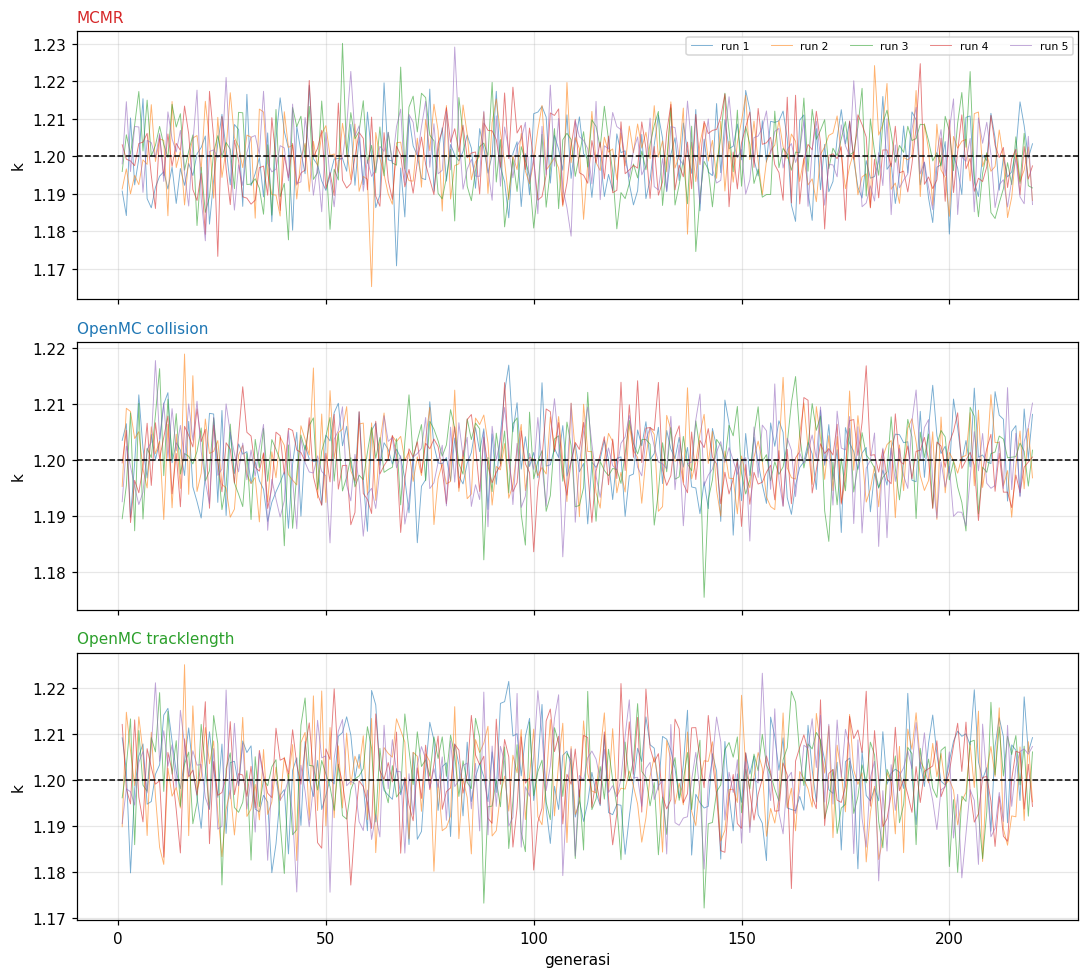

In [5]:
colors={'MCMR':'C3','OpenMC collision':'C0','OpenMC tracklength':'C2'}
fig,axs=plt.subplots(3,1,figsize=(10,9),sharex=True)
for ax,(m,c) in zip(axs,colors.items()):
    for r,g in est[est.method==m].groupby('run'):
        ax.plot(g.generation,g.k,lw=.6,alpha=.6,label=f'run {r}')
    ax.axhline(K_REF,color='k',ls='--',lw=1); ax.set_ylabel('k'); ax.set_title(m,loc='left',fontsize=10,color=c)
axs[0].legend(ncol=5,fontsize=7); axs[-1].set_xlabel('generasi'); plt.tight_layout(); plt.show()

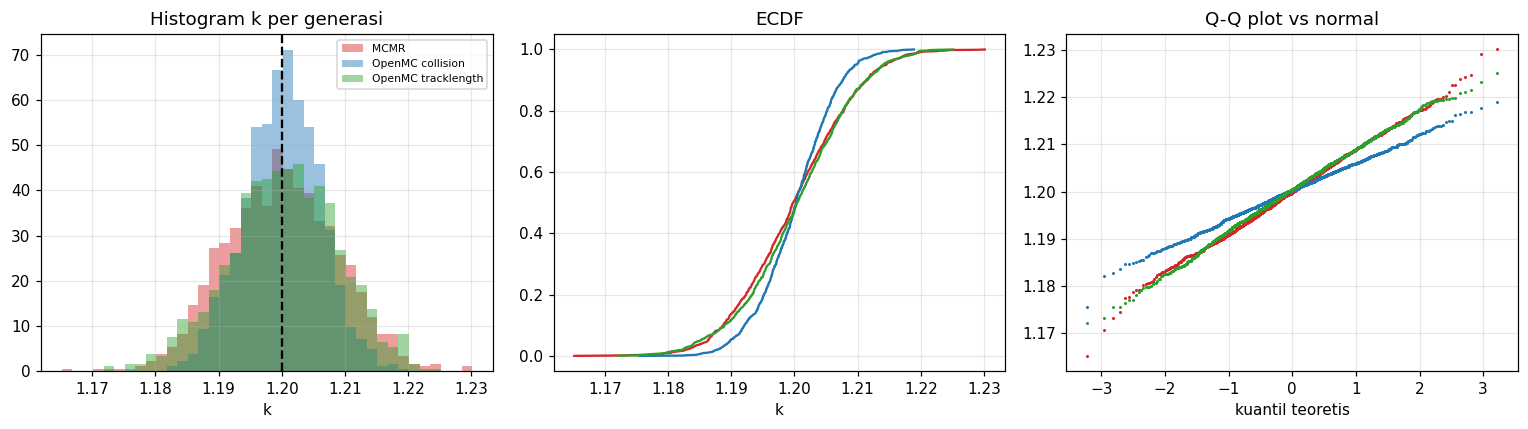

In [6]:
fig,ax=plt.subplots(1,3,figsize=(14,4))
bins=np.linspace(est.k.min(),est.k.max(),40)
for m,c in colors.items():
    x=est[est.method==m].k
    ax[0].hist(x,bins=bins,alpha=.45,color=c,density=True,label=m)
    xs=np.sort(x); ax[1].plot(xs,np.arange(1,len(xs)+1)/len(xs),color=c,label=m)
    (osm,osr),(sl,ic,r)=stats.probplot(x,dist='norm'); ax[2].plot(osm,osr,'.',ms=2,color=c,label=m)
ax[0].axvline(K_REF,color='k',ls='--'); ax[0].set_title('Histogram k per generasi'); ax[0].legend(fontsize=7)
ax[1].set_title('ECDF'); ax[2].set_title('Q-Q plot vs normal')
for a in ax: a.set_xlabel('k' if a is not ax[2] else 'kuantil teoretis')
plt.tight_layout(); plt.show()

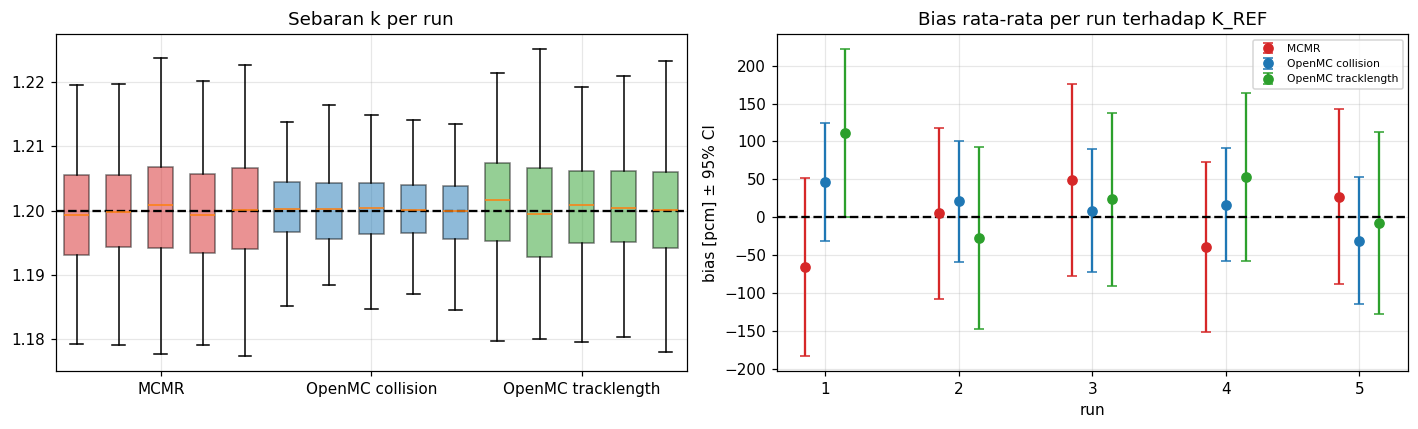

In [7]:
# Box plot per run + rata-rata run dengan error bar (SE dalam-run)
fig,ax=plt.subplots(1,2,figsize=(13,4))
data=[est[(est.method==m)&(est.run==r)].k for m in colors for r in range(1,6)]
pos=[i+1+0.0 for i in range(len(data))]
bp=ax[0].boxplot(data,positions=pos,widths=.6,patch_artist=True,showfliers=False)
for i,b in enumerate(bp['boxes']): b.set_facecolor(list(colors.values())[i//5]); b.set_alpha(.5)
ax[0].axhline(K_REF,color='k',ls='--'); ax[0].set_xticks([3,8,13]); ax[0].set_xticklabels(list(colors)); ax[0].set_title('Sebaran k per run')
for j,(m,c) in enumerate(colors.items()):
    p=per_run.loc[m]; ax[1].errorbar(p.index+(j-1)*.15,(p['mean']-K_REF)*1e5,yerr=1.96*p.SE*1e5,fmt='o',color=c,capsize=3,label=m)
ax[1].axhline(0,color='k',ls='--'); ax[1].set_xlabel('run'); ax[1].set_ylabel('bias [pcm] ± 95% CI'); ax[1].legend(fontsize=7)
ax[1].set_title('Bias rata-rata per run terhadap K_REF'); plt.tight_layout(); plt.show()

## 3. Uji bias terhadap nilai referensi
Karena autokorelasi antar-generasi diperkirakan sangat kecil (lihat bagian 6), generasi dianggap hampir independen dan $SE=s/\sqrt N$.
Untuk kehati-hatian, uji juga dilakukan pada **rata-rata per-run** (n=5), yang pasti independen antar-run.
Uji TOST memeriksa apakah bias *terbukti* lebih kecil dari margin `TOL_PCM`, bukan sekadar "tidak terbukti berbeda".

In [8]:
def tost(x, ref, tol):
    n=len(x); m=x.mean(); se=x.std(ddof=1)/np.sqrt(n)
    p_lo=1-stats.t.cdf((m-(ref-tol))/se,n-1); p_hi=stats.t.cdf((m-(ref+tol))/se,n-1)
    return max(p_lo,p_hi)
rows=[]
for m,g in est.groupby('method'):
    x=g.k.values; n=len(x); se=x.std(ddof=1)/np.sqrt(n); t=stats.t.ppf(1-ALPHA/2,n-1)
    rm=g.groupby('run').k.mean().values; nr=len(rm); ser=rm.std(ddof=1)/np.sqrt(nr)
    rows.append(dict(method=m, bias_pcm=(x.mean()-K_REF)*1e5, CI95_lo_pcm=(x.mean()-t*se-K_REF)*1e5, CI95_hi_pcm=(x.mean()+t*se-K_REF)*1e5,
        p_ttest_pooled=stats.ttest_1samp(x,K_REF).pvalue, p_ttest_runmeans=stats.ttest_1samp(rm,K_REF).pvalue,
        p_TOST=tost(x,K_REF,TOL_PCM*1e-5), SE_pcm=se*1e5, SE_runmeans_pcm=ser*1e5))
bias=pd.DataFrame(rows).set_index('method'); bias.round(4)

,bias_pcm,CI95_lo_pcm,CI95_hi_pcm,p_ttest_pooled,p_ttest_runmeans,p_TOST,SE_pcm,SE_runmeans_pcm
method,,,,,,,,
MCMR,-4.5048,-56.7423,47.7326,0.8657,0.8412,0.2803,26.6229,21.0792
OpenMC collision,12.7309,-22.7675,48.2293,0.4818,0.3681,0.3440,18.0918,12.5604
OpenMC tracklength,30.6480,-20.7871,82.0832,0.2426,0.2743,0.6577,26.2140,24.2104


## 4. Konsistensi antar-run (apakah variabilitas antar-run sesuai dengan yang diharapkan dari noise statistik?)

In [9]:
# One-way ANOVA + rasio varians antar-run vs dalam-run. Jika kode benar & seed independen, p-ANOVA tinggi.
rows=[]
for m,g in est.groupby('method'):
    groups=[h.k.values for _,h in g.groupby('run')]
    F,p=stats.f_oneway(*groups)
    rm=np.array([x.mean() for x in groups]); n=len(groups[0])
    expected_var=np.mean([x.var(ddof=1) for x in groups])/n
    # chi2: (R-1)*var(run means)/expected
    chi2=(len(rm)-1)*rm.var(ddof=1)/expected_var; p_chi=1-stats.chi2.cdf(chi2,len(rm)-1)
    rows.append(dict(method=m,F_ANOVA=F,p_ANOVA=p,var_runmeans=rm.var(ddof=1),var_expected=expected_var,ratio=rm.var(ddof=1)/expected_var))
pd.DataFrame(rows).set_index('method').round(6)

,F_ANOVA,p_ANOVA,var_runmeans,var_expected,ratio
method,,,,,
MCMR,0.626047,0.643989,0.0,0.0,0.626047
OpenMC collision,0.481088,0.749658,0.0,0.0,0.481088
OpenMC tracklength,0.852516,0.492024,0.0,0.0,0.852516


## 5. Perbandingan presisi dan distribusi MCMR vs OpenMC
Perbandingan varians per-generasi hanya adil jika **jumlah partikel per generasi sama**. Pastikan itu dulu.
Estimator *collision* di OpenMC lazim punya varians lebih kecil daripada tracklength pada medium tak-hingga, jadi pembanding yang paling relevan
untuk MCMR adalah estimator yang **setipe** dengan yang dipakai di kode Anda.

In [10]:
def var_ratio_ci(x,y,B=5000,seed=0):
    rng=np.random.default_rng(seed); r=[]
    for _ in range(B):
        r.append(rng.choice(x,len(x)).var(ddof=1)/rng.choice(y,len(y)).var(ddof=1))
    return np.percentile(r,[2.5,97.5])
x=est[est.method=='MCMR'].k.values
rows=[]
for m in ['OpenMC collision','OpenMC tracklength']:
    y=est[est.method==m].k.values
    F=x.var(ddof=1)/y.var(ddof=1); dfx,dfy=len(x)-1,len(y)-1
    p_F=2*min(stats.f.cdf(F,dfx,dfy),1-stats.f.cdf(F,dfx,dfy))
    lo,hi=var_ratio_ci(x,y)
    rows.append(dict(vs=m, var_ratio=F, CI95_lo=lo, CI95_hi=hi, p_F=p_F, p_Levene=stats.levene(x,y).pvalue,
        p_Welch_mean=stats.ttest_ind(x,y,equal_var=False).pvalue, p_MannWhitney=stats.mannwhitneyu(x,y).pvalue,
        p_KS=stats.ks_2samp(x,y).pvalue, std_MCMR=x.std(ddof=1), std_other=y.std(ddof=1)))
cmp_=pd.DataFrame(rows).set_index('vs'); cmp_.round(5)

,var_ratio,CI95_lo,CI95_hi,p_F,p_Levene,p_Welch_mean,p_MannWhitney,p_KS,std_MCMR,std_other
vs,,,,,,,,,,
OpenMC collision,2.16544,1.92265,2.44266,0.00000,0.000,0.59239,0.47184,0.00000,0.00883,0.00600
OpenMC tracklength,1.03144,0.91939,1.15772,0.60798,0.505,0.34688,0.20688,0.29134,0.00883,0.00869


,MCMR,collision,tracklength
run,,,
1,0.00887,0.00588,0.00836
2,0.00854,0.00604,0.00904
3,0.00952,0.00615,0.00865
4,0.00847,0.00559,0.00836
5,0.00874,0.00634,0.00905


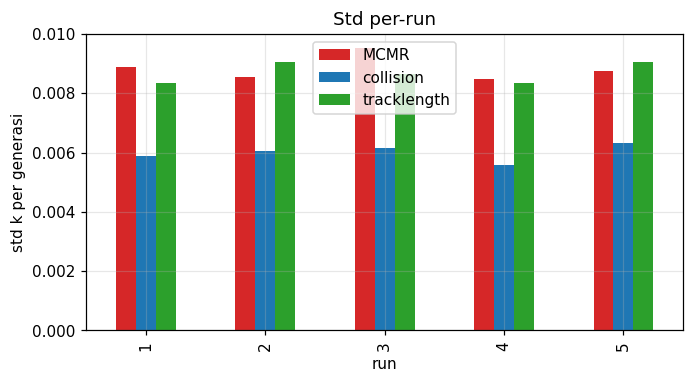

In [11]:
# Per-run vs per-run juga dibandingkan, supaya tidak hanya bergantung pada data yang di-pool
rows=[]
for r in range(1,6):
    rows.append(dict(run=r, MCMR=est[(est.method=='MCMR')&(est.run==r)].k.std(),
                     collision=est[(est.method=='OpenMC collision')&(est.run==r)].k.std(),
                     tracklength=est[(est.method=='OpenMC tracklength')&(est.run==r)].k.std()))
sd=pd.DataFrame(rows).set_index('run'); display(sd.round(5))
sd.plot(kind='bar',figsize=(7,3.5),color=['C3','C0','C2']); plt.ylabel('std k per generasi'); plt.title('Std per-run'); plt.show()

## 6. Autokorelasi, konvergensi, dan sensitivitas terhadap generasi awal yang dibuang

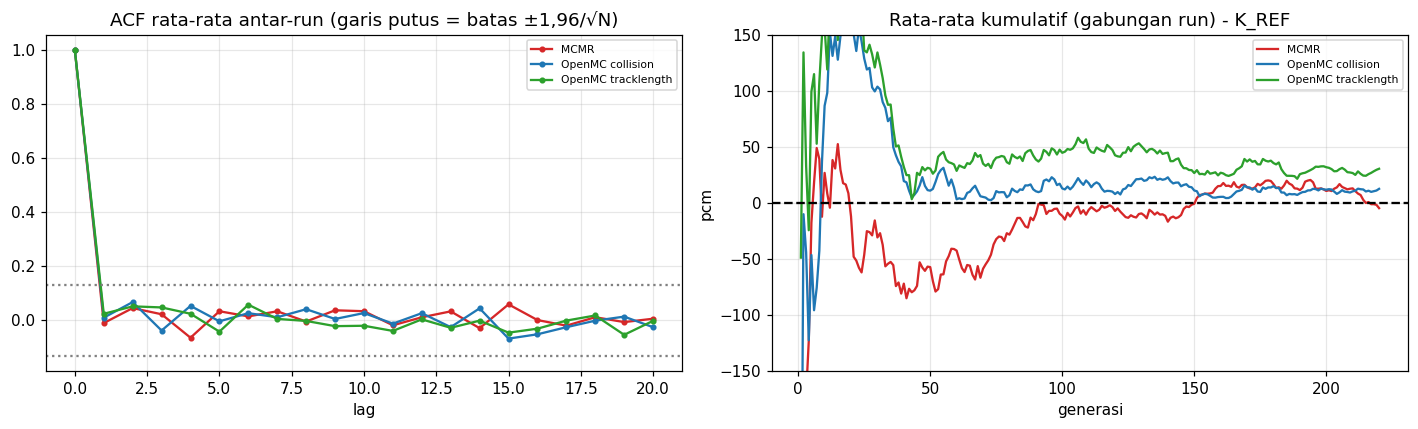

In [17]:
from statsmodels.tsa.stattools import acf
fig,ax=plt.subplots(1,2,figsize=(13,4))
for m,c in colors.items():
    A=np.mean([acf(g.k.values,nlags=20,fft=True) for _,g in est[est.method==m].groupby('run')],axis=0)
    ax[0].plot(range(21),A,'o-',ms=3,color=c,label=m)
ax[0].axhline(1.96/np.sqrt(220),color='gray',ls=':'); ax[0].axhline(-1.96/np.sqrt(220),color='gray',ls=':')
ax[0].set_title('ACF rata-rata antar-run (garis putus = batas ±1,96/√N)'); ax[0].set_xlabel('lag'); ax[0].legend(fontsize=7)
for m,c in colors.items():
    rm=est[est.method==m].pivot(index='generation',columns='run',values='k').expanding().mean().mean(axis=1)
    ax[1].plot(rm.index,(rm-K_REF)*1e5,color=c,label=m)
ax[1].axhline(0,color='k',ls='--'); ax[1].set_ylim(-150,150); ax[1].set_title('Rata-rata kumulatif (gabungan run) - K_REF'); ax[1].set_xlabel('generasi'); ax[1].set_ylabel('pcm'); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [18]:
# Sensitivitas: bias & SE bila N generasi awal dibuang, + uji Geweke sederhana (10% awal vs 50% akhir) per run
rows=[]
for m in colors:
    g=long[long.method==m]
    for nd in [0,5,10,20,50,100]:
        x=g[g.generation>nd].k.values
        rows.append(dict(method=m,discard=nd,bias_pcm=(x.mean()-K_REF)*1e5,SE_pcm=x.std(ddof=1)/np.sqrt(len(x))*1e5))
sens=pd.DataFrame(rows).pivot(index='discard',columns='method'); display(sens.round(2))

rows=[]
for m in colors:
    for r,g in long[long.method==m].groupby('run'):
        k=g.sort_values('generation').k.values; a,b=k[:int(.1*len(k))],k[-int(.5*len(k)):]
        z=(a.mean()-b.mean())/np.sqrt(a.var(ddof=1)/len(a)+b.var(ddof=1)/len(b)); rows.append(dict(method=m,run=r,z_geweke=z))
gw=pd.DataFrame(rows).pivot(index='run',columns='method',values='z_geweke'); display(gw.round(2))
print('Jumlah |z|>1.96 per metode:', (gw.abs()>1.96).sum().to_dict(), ' (ekspektasi ~0,25 dari 5 run bila konvergen)')

bias_pcm                                     SE_pcm                   \
method      MCMR OpenMC collision OpenMC tracklength   MCMR OpenMC collision   
discard                                                                        
0          -4.50            12.73              30.65  26.62            18.09   
5          -4.20            14.10              29.05  26.99            18.20   
10         -6.00             9.20              24.62  27.36            18.38   
20         -3.77            -1.58              15.60  28.15            18.65   
50         10.97            13.21              30.61  29.95            20.28   
100         1.25            12.43              18.78  34.77            23.95   

                            
method  OpenMC tracklength  
discard                     
0                    26.21  
5                    26.48  
10                   26.81  
20                   27.41  
50                   29.67  
100                  35.11

method,MCMR,OpenMC collision,OpenMC tracklength
run,,,
1,-2.31,0.64,0.66
2,-0.37,1.19,0.70
3,0.85,0.69,1.32
4,-0.10,0.22,-0.32
5,0.51,1.27,1.89


Jumlah |z|>1.96 per metode: {'MCMR': 1, 'OpenMC collision': 0, 'OpenMC tracklength': 0}  (ekspektasi ~0,25 dari 5 run bila konvergen)


## 7. Figure of Merit (FOM)
$FOM = 1/(\sigma_{\bar k}^2\,T)$. Isi `T_MCMR` dan `T_OPENMC` (detik, untuk run dengan jumlah generasi/partikel yang sama) pada sel parameter agar bagian ini aktif.

In [19]:
if T_MCMR and T_OPENMC:
    out={}
    for m,T in [('MCMR',T_MCMR),('OpenMC collision',T_OPENMC),('OpenMC tracklength',T_OPENMC)]:
        s=est[est.method==m].groupby('run').k.mean().std(ddof=1)  # std antar-run mean
        out[m]=1/(est[est.method==m].k.std(ddof=1)**2/ (220-N_DISCARD) * T)
    print(pd.Series(out).apply(lambda v:f'{v:.3e}'))
else:
    print('T_MCMR / T_OPENMC belum diisi -> FOM dilewati.')

T_MCMR / T_OPENMC belum diisi -> FOM dilewati.


## 8. Ringkasan dan kesimpulan otomatis

In [20]:
m_b=bias.loc['MCMR']; ok_bias = (m_b.p_ttest_pooled>ALPHA) and (m_b.p_ttest_runmeans>ALPHA)
equiv = m_b.p_TOST<ALPHA
print('=== BIAS MCMR terhadap K_REF = %.5f ===' % K_REF)
print(f' bias = {m_b.bias_pcm:+.1f} pcm, CI95 [{m_b.CI95_lo_pcm:+.1f}, {m_b.CI95_hi_pcm:+.1f}] pcm')
print(f' t-test pooled p={m_b.p_ttest_pooled:.3f}, run-means p={m_b.p_ttest_runmeans:.3f} -> {"tidak ada bias signifikan" if ok_bias else "BIAS SIGNIFIKAN"}')
print(f' TOST (+-{TOL_PCM} pcm) p={m_b.p_TOST:.3f} -> {"setara dalam margin" if equiv else "belum terbukti setara dalam margin (presisi statistik kurang / margin terlalu ketat)"}')
for v,r in cmp_.iterrows():
    sig = r.p_F<ALPHA
    print(f'\n=== MCMR vs {v} ===')
    print(f' rasio varians = {r.var_ratio:.2f} (CI95 {r.CI95_lo:.2f}-{r.CI95_hi:.2f}), p_F={r.p_F:.3g} -> ',
          'varians BERBEDA signifikan' if sig else 'varians tidak berbeda signifikan')
    print(f' rata-rata beda? Welch p={r.p_Welch_mean:.3f}; bentuk distribusi KS p={r.p_KS:.3f}')

=== BIAS MCMR terhadap K_REF = 1.20000 ===
 bias = -4.5 pcm, CI95 [-56.7, +47.7] pcm
 t-test pooled p=0.866, run-means p=0.841 -> tidak ada bias signifikan
 TOST (+-20 pcm) p=0.280 -> belum terbukti setara dalam margin (presisi statistik kurang / margin terlalu ketat)

=== MCMR vs OpenMC collision ===
 rasio varians = 2.17 (CI95 1.92-2.44), p_F=2.22e-16 ->  varians BERBEDA signifikan
 rata-rata beda? Welch p=0.592; bentuk distribusi KS p=0.000

=== MCMR vs OpenMC tracklength ===
 rasio varians = 1.03 (CI95 0.92-1.16), p_F=0.608 ->  varians tidak berbeda signifikan
 rata-rata beda? Welch p=0.347; bentuk distribusi KS p=0.291


## Catatan interpretasi
- **Tidak signifikan ≠ terbukti benar.** Dengan 1100 generasi, SE rata-rata ≈ 27 pcm; bias di bawah ±50 pcm praktis tidak bisa dibedakan dari nol. Untuk menyatakan akurasi pada level ~10 pcm diperlukan generasi aktif jauh lebih banyak (SE ∝ 1/√N).
- Benchmark ini memvalidasi eigenvalue pada **satu problem**. Validasi lebih kuat: variasikan komposisi/geometri, bandingkan juga laju reaksi per grup / spektrum fluks, bukan hanya k.
- Kesetaraan ukuran sampel (partikel per generasi) antara MCMR dan OpenMC wajib dipastikan agar perbandingan varians bermakna.